<a href="https://colab.research.google.com/github/SantiagoOsorioTamayo/Practica_ML_Python_Hongo/blob/main/Practica_ML_Hongos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importar librerías para el procesamiento de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from sklearn.datasets import fetch_openml
mush = fetch_openml(name='mushroom', as_frame=True) # Buscar por nombre es más fiable
datos = mush.frame

/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_openml.py:323: UserWarning: Multiple active versions of the dataset matching the name mushroom exist. Versions may be fundamentally different, returning version 1. Available versions:
- version 1, status: active
  url: https://www.openml.org/search?type=data&id=24
- version 3, status: active
  url: https://www.openml.org/search?type=data&id=43922

  warn(warning_msg)


In [ ]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   cap-shape                 8124 non-null   category
 1   cap-surface               8124 non-null   category
 2   cap-color                 8124 non-null   category
 3   bruises%3F                8124 non-null   category
 4   odor                      8124 non-null   category
 5   gill-attachment           8124 non-null   category
 6   gill-spacing              8124 non-null   category
 7   gill-size                 8124 non-null   category
 8   gill-color                8124 non-null   category
 9   stalk-shape               8124 non-null   category
 10  stalk-root                5644 non-null   category
 11  stalk-surface-above-ring  8124 non-null   category
 12  stalk-surface-below-ring  8124 non-null   category
 13  stalk-color-above-ring    8124 non-null   catego

In [ ]:
print(datos['class'].unique())
# e = edible, comestible
# p = poisonous, venenoso

['p', 'e']
Categories (2, object): ['e', 'p']


In [ ]:
print(datos)

     cap-shape cap-surface cap-color bruises%3F odor gill-attachment  \
0            x           s         n          t    p               f   
1            x           s         y          t    a               f   
2            b           s         w          t    l               f   
3            x           y         w          t    p               f   
4            x           s         g          f    n               f   
...        ...         ...       ...        ...  ...             ...   
8119         k           s         n          f    n               a   
8120         x           s         n          f    n               a   
8121         f           s         n          f    n               a   
8122         k           y         n          f    y               f   
8123         x           s         n          f    n               a   

     gill-spacing gill-size gill-color stalk-shape  ...  \
0               c         n          k           e  ...   
1               c

In [ ]:
datos['class'].value_counts(dropna=False)

,count
class,
e,4208
p,3916


In [ ]:
# Balancear la variable respuesta con SMOTENC, SMOTE o RandomOverSampler
# Usar SMOTENC(random_state=10,categorical_features=(Aqui estan las columnas categoricas)) cuando haya columnas categóricas y numéricas (sin contar a la que se predicirá)
# Usar SMOTE(random_state=10) cuando solo haya columnas numéricas
# Usar RandomOverSampler cuando solo haya columnas categóricas
# Escoge aleatoriamente registros de cada categoría y los duplica hasta alcanzar la frecuencia de la
# categoría dominante (4208)

# from imblearn.over_sampling import SMOTENC
# from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import RandomOverSampler

In [ ]:
x=datos.drop("class",axis=1) # Variables predictoras (axis=1, osea, que es una columna)
y=datos["class"] # Variable respuesta

# En un caso donde haya muchas columnas categóricas, para usar SMOTENC, se puede usar lo siguiente
# Detectar las columnas categóricas automáticamente
# En el dataset de hongos, TODAS las columnas de x son strings (object)
# categorical_indices = x.select_dtypes(include=['object', 'category']).columns.tolist()

# Obtener sus índices numéricos (posiciones en la tabla)
# categorical_indices = [x.columns.get_loc(col) for col in columnas_categoricas]

sm=RandomOverSampler(random_state=10) # Sólo hay columnas categóricas, usamos RandomOverSampler
x_bal,y_bal=sm.fit_resample(x,y)

In [ ]:
# creamos un dataframe con los datos balanceados
datos_bal=pd.concat([x_bal,y_bal],axis=1)

In [ ]:
datos_bal['class'].value_counts(dropna=False)

,count
class,
e,4208
p,4208


In [ ]:
# Para mapear de forma más eficiente y rápida, en vez de mapear con map, se usa dos tipos de mapeadores
# OrdinalEncoder: se usa para mapear registros que tenga una jerarquia u orden en las categorías (por ejemplo, tamaños como pequeño, mediano, grande)
# OneHotEncoder: se usa para mapear registros que no tengan un orden específico (que sean más independientes)

# from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder # En este caso no existe orden, se usa OneHotEncoder

In [ ]:
# Con OrdinalEncoder
# Suponiendo que ya tienes 'x' con las columnas categóricas originales
# encoder = OrdinalEncoder()

# Transformamos todas las columnas de 'x' a números
# x_codificado = encoder.fit_transform(x)

# Convertimos el resultado a DataFrame para que sea más cómodo
# x = pd.DataFrame(x_codificado, columns=x.columns)

# print(x.head()) # Ahora todas las columnas son numéricas (0, 1, 2...)

In [ ]:
# Con OneHotEncoder
# Inicializamos el codificador con sparse_output=False para que nos devuelva un array denso
encoder = OneHotEncoder(sparse_output=False)

# Transformamos
x_bal_codificado = encoder.fit_transform(x_bal)

# Obtenemos los nombres de las nuevas columnas (ej: 'cap-shape_bell', 'cap-shape_conical', etc.)
nombres_columnas = encoder.get_feature_names_out(x_bal.columns)

# Convertimos a DataFrame
x_bal = pd.DataFrame(x_bal_codificado, columns=nombres_columnas)

print(x_bal.head()) # Ahora cada columna es 0 o 1

   cap-shape_b  cap-shape_c  cap-shape_f  cap-shape_k  cap-shape_s  \
0          0.0          0.0          0.0          0.0          0.0   
1          0.0          0.0          0.0          0.0          0.0   
2          1.0          0.0          0.0          0.0          0.0   
3          0.0          0.0          0.0          0.0          0.0   
4          0.0          0.0          0.0          0.0          0.0   

   cap-shape_x  cap-surface_f  cap-surface_g  cap-surface_s  cap-surface_y  \
0          1.0            0.0            0.0            1.0            0.0   
1          1.0            0.0            0.0            1.0            0.0   
2          0.0            0.0            0.0            1.0            0.0   
3          1.0            0.0            0.0            0.0            1.0   
4          1.0            0.0            0.0            1.0            0.0   

   ...  population_s  population_v  population_y  habitat_d  habitat_g  \
0  ...           1.0           0.0  

In [ ]:
# Reconstruir datos_bal con las columnas numéricas
datos_bal = pd.concat([x_bal, y_bal], axis=1)

# Redefinimos x_bal y y_bal desde el dataframe 'datos_bal' ya codificado numéricamente.
x_bal = datos_bal.drop("class", axis=1)
y_bal = datos_bal["class"]

In [ ]:
datos_bal

,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w,class
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,p
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,e
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,e
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,p
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,e
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8411,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,p
8412,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,p
8413,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,p
8414,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,p


In [ ]:
# Importar librerías para el aprendizaje de máquina (Machine Learning)
from sklearn.model_selection import cross_validate # Validación cruzada
from sklearn import tree # Árboles de decisión (Clasificación)

In [ ]:
x=datos.drop("class",axis=1) # Variables predictoras
y=datos["class"] # Variable respuesta
modelo=tree.DecisionTreeClassifier(criterion="entropy",min_samples_leaf=2,max_depth=7)
# Entropía: mide el grado de impureza de los datos en una ramificación del árbol, entre más cercano a cero,
# más uniformes son los pacientes de esa rama.
# min_samples_leaf: Mínimo número de hojas en una rama
# max_depth: máximo número de niveles de profundidad del árbol

In [ ]:
puntaje=cross_validate(modelo,x_bal,y_bal,cv=10,scoring=('f1_weighted','accuracy','precision_weighted',
                                                 'recall_weighted'))
# https://www.ibm.com/es-es/think/topics/confusion-matrix

In [ ]:
# Como se utilizó Cross Validation, se deben promediar los resultados de las medidas de desempeño
print("F1: ",puntaje["test_f1_weighted"].mean())
print("Accuracy: ",puntaje["test_accuracy"].mean())
print("precision_weighted: ",puntaje["test_precision_weighted"].mean())
print("recall_weighted: ",puntaje["test_recall_weighted"].mean())

F1:  0.9986923771047416
Accuracy:  0.9986924569495088
precision_weighted:  0.9987127582474702
recall_weighted:  0.9986924569495088


In [ ]:
# Estas medidas de desempeño son mejores cuando son más cercanas a uno, y tienen sentido cuando se comparan
# con las mismas medidas de otros modelos, para seleccionar el mejor.

modelo=modelo.fit(x_bal,y_bal) # Ajustar el modelo a los datos balanceados

In [ ]:
# Producto de datos --- Graficar el Árbol de Clasificación para tomar decisiones
from IPython.display import Image # Librería gráfica
from sklearn.tree import export_graphviz # Modelo de grafos
import pydotplus # Objeto gráfico
from six import StringIO # Librería gráfica

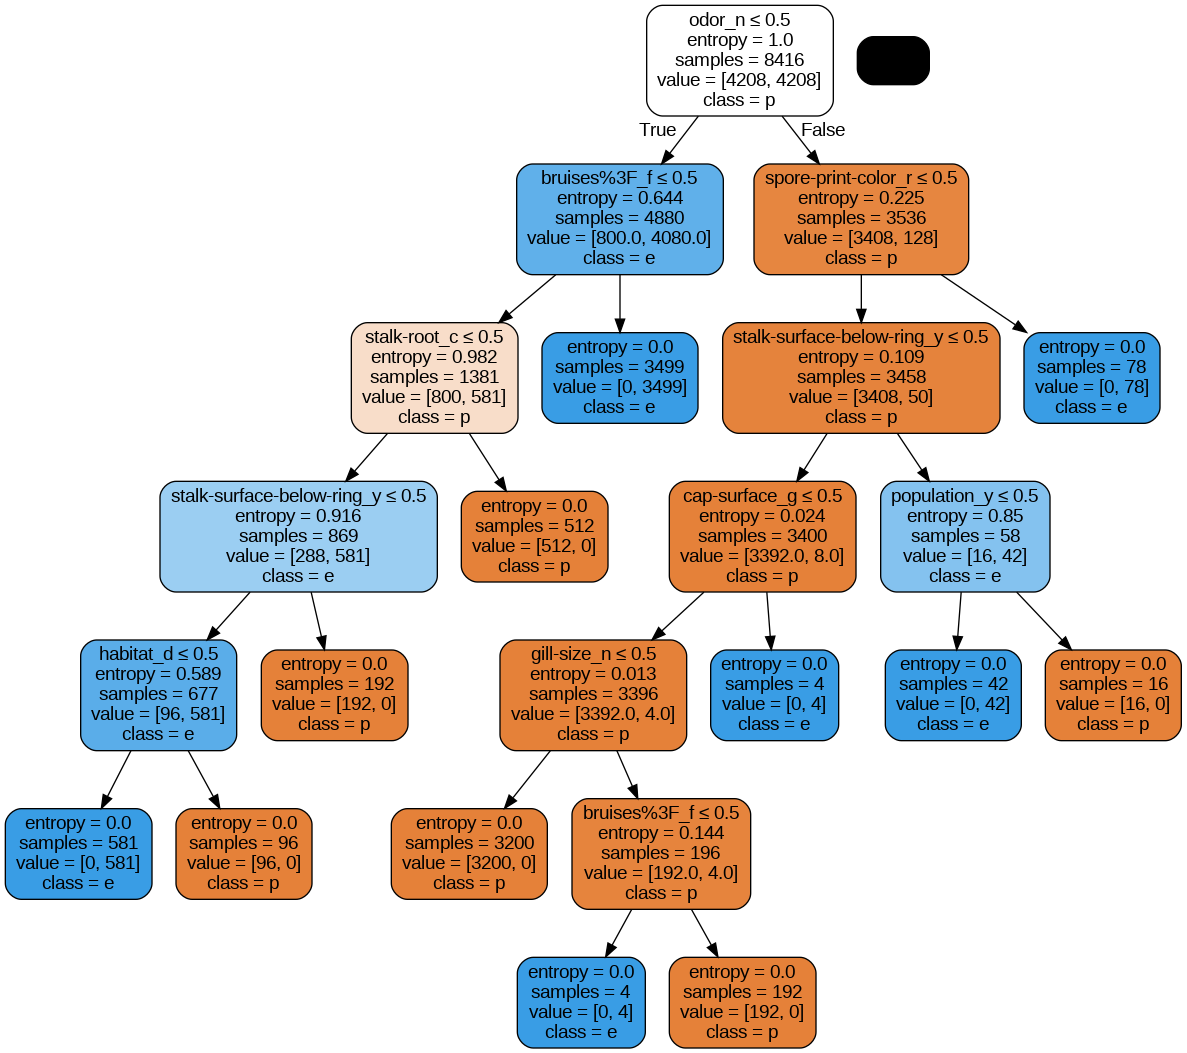

In [ ]:
dot_datos=StringIO()
var_predictoras=nombres_columnas # Variables predictoras al usar OneHotEncoder
nombres_clases=['p','e']
export_graphviz(modelo,feature_names=var_predictoras,out_file=dot_datos,
                class_names=nombres_clases,filled=True,rounded=True,special_characters=True)
grafica=pydotplus.graph_from_dot_data(dot_datos.getvalue())
Image(grafica.create_png())